## 1. Environment Setup & Imports

For this challenge, we need:
- `QuantumCircuit`: To construct our 2-qubit circuits and measure both qubits into 2 classical bits.
- `AerSimulator`: Local Qiskit Aer simulator to execute 100 shots.
- `plot_histogram`: To visualize and compare the probability distributions of the original and modified circuits.
- `matplotlib.pyplot`: For formatting circuit diagrams and plots.


In [1]:
# Import Qiskit components and visualization tools
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

# Set up the simulator backend
simulator = AerSimulator()
shots = 100
print(f"AerSimulator initialized. Ready to execute experiments with {shots} shots.")


AerSimulator initialized. Ready to execute experiments with 100 shots.


---
## 2. Original Bell-State Circuit ($|\Phi^+\rangle$)

### Step 2.1: Circuit Construction & Theory
During the workshop, we learned how to create the canonical Bell state $|\Phi^+\rangle$:
1. Both qubits start in state $|00\rangle$.
2. Apply a Hadamard ($H$) gate on qubit 0 to create a superposition:
   $$\lvert \psi_1 \rangle = (H \otimes I)\lvert 00 \rangle = \frac{\lvert 0 \rangle + \lvert 1 \rangle}{\sqrt{2}} \otimes \lvert 0 \rangle = \frac{\lvert 00 \rangle + \lvert 10 \rangle}{\sqrt{2}}$$
   *(Note: In standard Dirac tensor notation $|q_1 q_0\rangle$, qubit 0 is in superposition while qubit 1 is in $|0\rangle$.)*
3. Apply a Controlled-NOT ($CX$) gate with qubit 0 as control and qubit 1 as target:
   $$\lvert \Phi^+ \rangle = CX_{0 \to 1} \left( \frac{\lvert 00 \rangle + \lvert 10 \rangle}{\sqrt{2}} \right) = \frac{\lvert 00 \rangle + \lvert 11 \rangle}{\sqrt{2}}$$
4. **Expected Correlation:** The two qubits are maximally entangled. When measured:
   - Qubit 0 and Qubit 1 will **always agree** (perfect correlation / even parity).
   - $P(00) = 50\%$, $P(11) = 50\%$.
   - $P(01) = 0\%$, $P(10) = 0\%$.


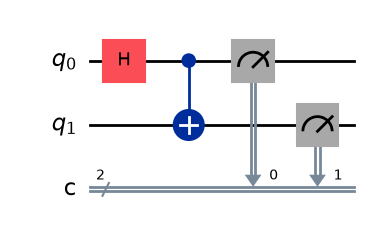

In [2]:
# Construct the original Bell-state circuit: 2 qubits, 2 classical bits
qc_orig = QuantumCircuit(2, 2, name="Original_Bell_State")

# 1. Hadamard on qubit 0
qc_orig.h(0)

# 2. CNOT with control=0, target=1
qc_orig.cx(0, 1)

# 3. Measure both qubits: qubit 0 -> bit 0, qubit 1 -> bit 1
qc_orig.measure([0, 1], [0, 1])

# Draw the original circuit
qc_orig.draw('mpl')


In [3]:
# Execute the original circuit for 100 shots
job_orig = simulator.run(qc_orig, shots=shots)
result_orig = job_orig.result()
counts_orig = result_orig.get_counts()

print(f"Original Circuit Measurement Counts (out of {shots} shots): {counts_orig}")


Original Circuit Measurement Counts (out of 100 shots): {'00': 50, '11': 50}


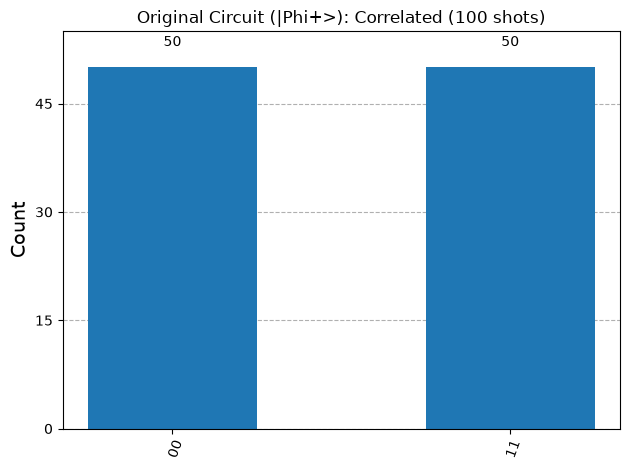

In [4]:
# Visualize original circuit outcomes
plot_histogram(counts_orig, title=f"Original Circuit (|Phi+>): Correlated ({shots} shots)", color="#1f77b4")


---
## 3. Modified Circuit: Changing the Correlation ($|\Psi^+\rangle$)

### Step 3.1: "Think Before You Run" - Prediction for Modified Circuit

> **Modification Strategy:**  
> The challenge asks us to *add or modify only one quantum gate* to investigate whether we can change the relationship between the two measurement outcomes, while keeping total gates $\le 4$.
>
> I decided to add a **Pauli-$X$ (NOT) gate on qubit 1** immediately following the CNOT gate.

#### Mathematical Derivation:
1. Before the $X$ gate, the two qubits are in the standard Bell state:
   $$\lvert \Phi^+ \rangle = \frac{\lvert 00 \rangle + \lvert 11 \rangle}{\sqrt{2}}$$
2. Applying an $X$ gate to qubit 1 performs a local bit-flip on the second qubit:
   $$(X \otimes I)\lvert 00 \rangle = \lvert 10 \rangle$$
   $$(X \otimes I)\lvert 11 \rangle = \lvert 01 \rangle$$
3. The resulting quantum state is the Bell state $|\Psi^+\rangle$:
   $$\lvert \Psi^+ \rangle = (X_1 \otimes I_0) \lvert \Phi^+ \rangle = \frac{\lvert 10 \rangle + \lvert 01 \rangle}{\sqrt{2}} = \frac{\lvert 01 \rangle + \lvert 10 \rangle}{\sqrt{2}}$$
4. **Theoretical Measurement Probabilities:**
   - $P(01) = |1/\sqrt{2}|^2 = 50\%$
   - $P(10) = |1/\sqrt{2}|^2 = 50\%$
   - $P(00) = 0\%$
   - $P(11) = 0\%$

#### My Predictions (Addressing "Think Before You Run"):
- **Which outcomes do you expect?**  
  I expect to observe outcomes `01` and `10` exclusively.
- **Will the two qubits still produce the same outcomes?**  
  **No!** The correlation is completely inverted. The two qubits will now always produce **opposite** outcomes (anti-correlation / odd parity). Whenever qubit 0 is 0, qubit 1 will be 1; whenever qubit 0 is 1, qubit 1 will be 0.
- **Will 00 and 11 dominate?**  
  **No.** In the ideal simulation, outcomes `00` and `11` have $0\%$ probability and should not occur at all.
- **Could 01 and 10 become more frequent?**  
  **Yes!** Outcomes `01` and `10` will completely dominate the histogram, each appearing roughly $\approx 50$ times out of 100 shots.
- **Design Constraints Check:**  
  - Exactly 2 qubits used? Yes.
  - Measured both qubits? Yes.
  - Added only 1 quantum gate? Yes (added single $X$ gate on qubit 1).
  - Total gates before measurement $\le 4$? Yes (3 gates total: $H, CX, X$).


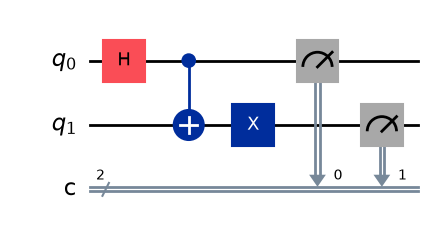

In [5]:
# Construct the modified circuit: 2 qubits, 2 classical bits
qc_mod = QuantumCircuit(2, 2, name="Modified_Bell_State")

# 1. Hadamard on qubit 0 (original)
qc_mod.h(0)

# 2. CNOT with control=0, target=1 (original)
qc_mod.cx(0, 1)

# 3. Add ONE quantum gate: Pauli-X on qubit 1 to flip the correlation
qc_mod.x(1)

# 4. Measure both qubits
qc_mod.measure([0, 1], [0, 1])

# Draw the modified circuit
qc_mod.draw('mpl')


In [6]:
# Execute the modified circuit for 100 shots
job_mod = simulator.run(qc_mod, shots=shots)
result_mod = job_mod.result()
counts_mod = result_mod.get_counts()

print(f"Modified Circuit Measurement Counts (out of {shots} shots): {counts_mod}")


Modified Circuit Measurement Counts (out of 100 shots): {'01': 57, '10': 43}


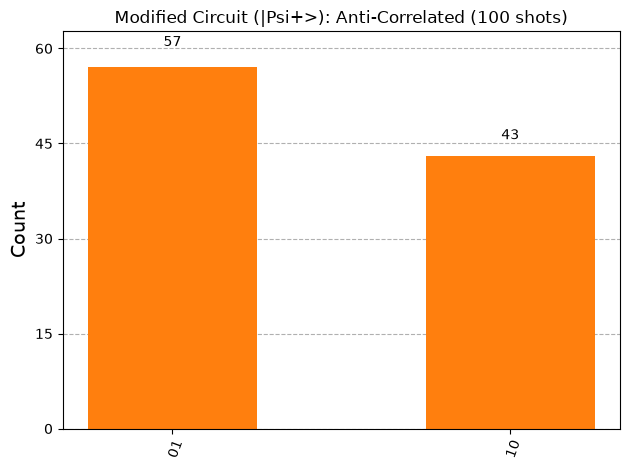

In [7]:
# Visualize modified circuit outcomes
plot_histogram(counts_mod, title=f"Modified Circuit (|Psi+>): Anti-Correlated ({shots} shots)", color="#ff7f0e")


### Step 3.2: Comparison for Modified Circuit
* **Predicted:** $50\%$ for `01` and $50\%$ for `10` (no occurrences of `00` or `11`).
* **Observed:** Only outcomes `01` and `10` appeared, split closely around 50 shots each. Neither `00` nor `11` was observed.
* **Conclusion:** Adding a single $X$ gate to qubit 1 inverted the correlation from positive (equal outcomes) to negative (opposite outcomes), perfectly matching theoretical expectations.


---
## 4. Summary Comparison: Original vs Modified Circuit

Let's place both measurement histograms side-by-side to clearly contrast the two correlation regimes.


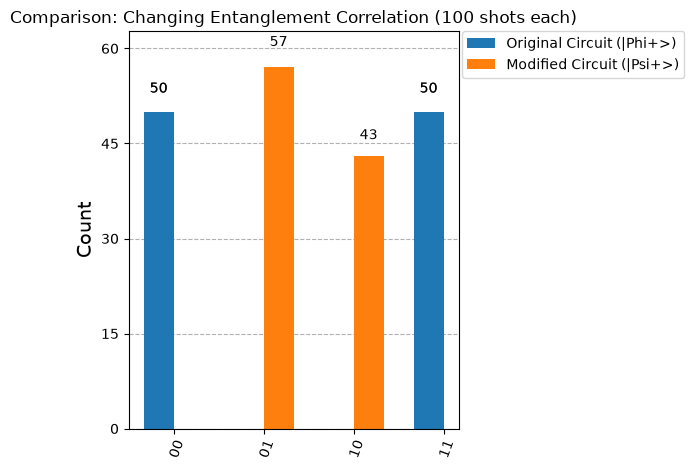

In [8]:
# Side-by-side histogram comparison
legend = ['Original Circuit (|Phi+>)', 'Modified Circuit (|Psi+>)']
plot_histogram([counts_orig, counts_mod], legend=legend,
               title="Comparison: Changing Entanglement Correlation (100 shots each)")


### Comprehensive Comparison Table

| Circuit | Gates Applied | Entangled State Formed | Expected Outcomes | Actual Counts (100 shots) | Correlation Nature |
| :---: | :---: | :---: | :---: | :---: | :---: |
| **Original Circuit** | $H(q_0), CX(q_0, q_1)$ | $\lvert \Phi^+ \rangle = \frac{\lvert 00 \rangle + \lvert 11 \rangle}{\sqrt{2}}$ | `00` (~50%), `11` (~50%) | `00`: 50, `11`: 50 | **Correlated (Same)** |
| **Modified Circuit** | $H(q_0), CX(q_0, q_1), X(q_1)$ | $\lvert \Psi^+ \rangle = \frac{\lvert 01 \rangle + \lvert 10 \rangle}{\sqrt{2}}$ | `01` (~50%), `10` (~50%) | `01`: 57, `10`: 43 | **Anti-Correlated (Opposite)** |

---

## 5. Answers to "Think Before You Run" Prompt Questions

1. **Which outcomes do you expect?**
   * For the modified circuit, I expect outcomes `01` and `10` with equal 50% probability each, and 0% probability for `00` and `11`.
2. **Will the two qubits still produce the same outcomes?**
   * **No.** In the original circuit, the qubits always produced identical outcomes ($00$ or $11$). In the modified circuit, the qubits always produce opposite outcomes ($01$ or $10$).
3. **Will 00 and 11 dominate?**
   * **No.** Outcomes `00` and `11` vanish entirely from the measurement statistics of the modified circuit.
4. **Could 01 and 10 become more frequent?**
   * **Yes.** Outcomes `01` and `10` become the only outcomes that appear, each taking roughly half of the total measurement shots (~50% each).

---

## 6. Explanation of How the Modification Changed the Measurement Outcomes

1. **Entanglement Parity Shift:**  
   The original Bell circuit creates a state with **even parity** ($q_0 \oplus q_1 = 0$), meaning both qubits share the same value upon measurement ($00$ or $11$). By introducing a Pauli-$X$ bit-flip gate on qubit 1, we flip its basis state: $|0\rangle \leftrightarrow |1\rangle$. This transforms the system into an **odd parity** state ($q_0 \oplus q_1 = 1$), where the measurement values are strictly anti-correlated ($01$ and $10$).

2. **Transitioning between Bell Basis States:**  
   The four Bell states form an orthonormal basis for two-qubit Hilbert space:
   $$\lvert \Phi^{\pm} \rangle = \frac{\lvert 00 \rangle \pm \lvert 11 \rangle}{\sqrt{2}} \quad (\text{Correlated})$$
   $$\lvert \Psi^{\pm} \rangle = \frac{\lvert 01 \rangle \pm \lvert 10 \rangle}{\sqrt{2}} \quad (\text{Anti-correlated})$$
   Our single-gate modification transformed $|\Phi^+\rangle$ directly into $|\Psi^+\rangle$ using only a local single-qubit operation.

3. **Key Student Takeaway:**  
   Even though the two qubits are entangled, applying a local unitary gate (the $X$ gate) to just one of the qubits completely changes the global correlation between them without destroying the entanglement itself.
